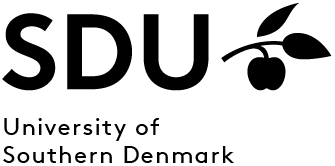
<br><br><br>
<p style="color: #789D4A;font-family: courier;font-size: 160%;text-align:center;">Optimization and Image Processing (E26)</p> 

<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Dr Till Leissner, Associate Professor</p> 
<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Mads Clausen Institute, University of Southern Denmark</p> 

In [2]:
import numpy as np
from scipy import ndimage as ndi

try:
    import oip
except Exception:
    oip = None

## Canny edge detection

Canny combines Gaussian smoothing, gradient calculation, non-maximum suppression and hysteresis.

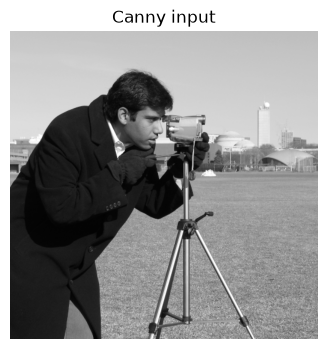

In [3]:
from skimage import data
from skimage.feature import canny
from skimage.util import img_as_float

image = img_as_float(data.camera())
oip.show_image(image, "Canny input", vmin=0, vmax=1);

In [33]:
my_image = oip.load_gray("alsik-normal.jpg", dtype=float)

In [27]:
### Loading your own image

from skimage import color, io, util

own_image = io.imread("alsik-normal.jpg")
print(type(own_image))
print(own_image.dtype,own_image.shape)

own_image_float = util.img_as_float(own_image).astype('float', copy=False)
own_image_float = color.rgb2gray(own_image_float)
print(own_image_float.dtype,own_image_float.shape)

own_image_8bit = util.img_as_uint(own_image)
own_image_8bit = color.rgb2gray(own_image_8bit)
print(own_image_8bit.dtype,own_image_8bit.shape)

<class 'numpy.ndarray'>
uint8 (1200, 1800, 3)
float64 (1200, 1800)
float64 (1200, 1800)


## Activity — Pair prediction (2 min)

Without running code, discuss what you expect when

- the Gaussian smoothing scale $\sigma$ is increased, and
- the high hysteresis threshold is increased.

**Which change is more likely to remove fine but real edges?**

Compare your prediction with a partner. Then run the next cell, changing one
parameter at a time. Be prepared to explain one result that did not match your
prediction.

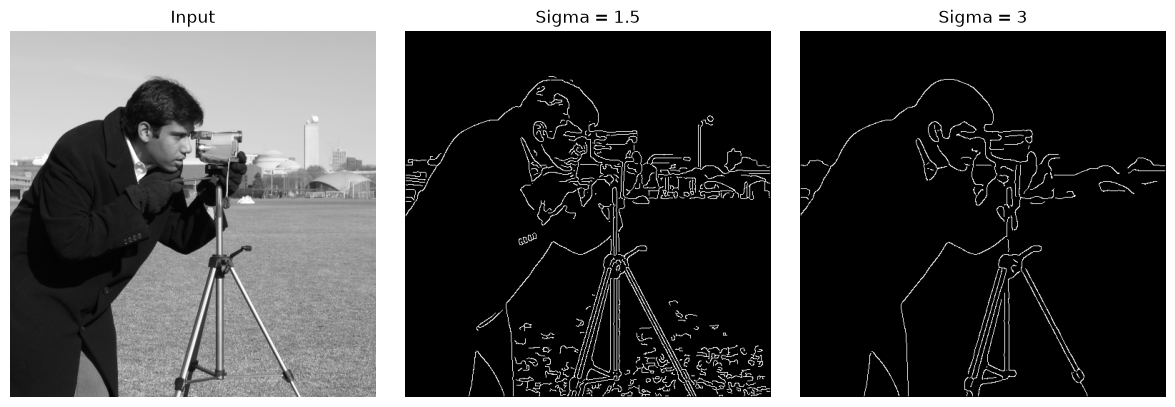

In [4]:
# Lecture fill-in (about 1 min): create the comparison with stronger smoothing.
# Keep the thresholds fixed so that only sigma changes.

sigma = 1.5
low = 0.10
high = 0.20

edges = canny(image, sigma=sigma, low_threshold=low, high_threshold=high)

smoother_edges = canny(image, sigma=3, low_threshold=low, high_threshold=high)

oip.show_images(image, edges, smoother_edges,
            titles=["Input", "Sigma = 1.5", "Sigma = 3"], vmin=0, vmax=1);


### Interactive demo — tune Canny parameters live

Now use the sliders to test the predictions. Change **one parameter at a time**
and discuss what changes in the edge map before moving to the next parameter.

In [6]:
import matplotlib.pyplot as plt
from ipywidgets import FloatSlider, interact

def canny_demo(sigma=1.5, low=0.10, high=0.20):
    if low >= high:
        print("Choose low < high.")
        return

    demo_edges = canny(
        image,
        sigma=sigma,
        low_threshold=low,
        high_threshold=high,
    )

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(image, cmap="gray")
    axes[0].set_title("Input")
    axes[1].imshow(demo_edges, cmap="gray")
    axes[1].set_title(
        f"Canny: sigma={sigma:.1f}, low={low:.2f}, high={high:.2f}"
    )
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

interact(
    canny_demo,
    sigma=FloatSlider(
        value=1.5, min=0.5, max=4.0, step=0.5,
        description="sigma",
    ),
    low=FloatSlider(
        value=0.10, min=0.02, max=0.30, step=0.02,
        description="low",
    ),
    high=FloatSlider(
        value=0.20, min=0.05, max=0.50, step=0.05,
        description="high",
    ),
);

interactive(children=(FloatSlider(value=1.5, description='sigma', max=4.0, min=0.5, step=0.5), FloatSlider(val…


More smoothing suppresses noise and small details, and can remove weak edges. Hysteresis retains weak candidate pixels only if connected through other candidates to a strong seed. Non-maximum suppression first makes candidate edges thin.


### Illustration of hysteresis 

Values below represent gradient magnitudes **after** non-maximum suppression, not image intensities. Predict which weak segment survives. `binary_propagation` illustrates the connectivity stage alone.

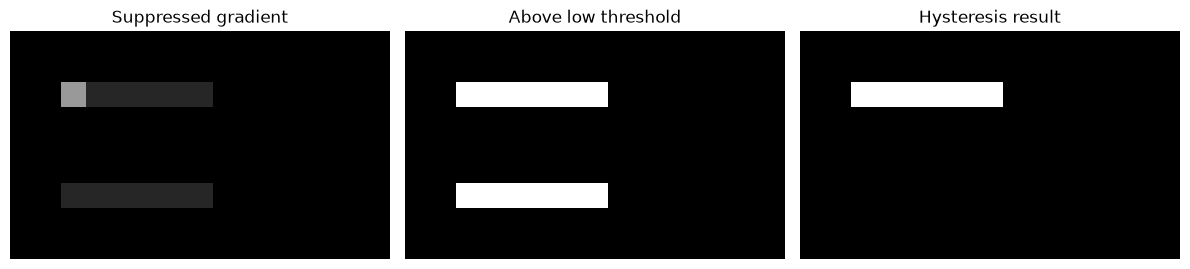

In [7]:
strength = np.zeros((9, 15))
strength[2, 2:8] = 0.15
strength[2, 2] = 0.60  # strong seed attached to weak pixels
strength[6, 2:8] = 0.15  # equally weak, but disconnected

weak_or_strong = strength >= low
strong = strength >= high
linked = ndi.binary_propagation(strong, structure=np.ones((3, 3)), mask=weak_or_strong)
oip.show_images(strength, weak_or_strong, linked,
            titles=["Suppressed gradient", "Above low threshold", "Hysteresis result"],
            vmin=0, vmax=1);

## Optional programming challenge

Interested in the actual implementation? Continue with
[`l05-6_optional_programming.ipynb`](l05-6_optional_programming.ipynb).
The optional notebook follows the Burger & Burge algorithm structure and keeps
the implementation-focused, scored exercises separate from the lecture demo.

## Assignment — tune and validate Canny

Work in pairs if possible.

1. Choose an image: preferably your own image or a microscopy/materials image;
   otherwise use another `skimage.data` image.
2. Run Canny with at least **three** parameter combinations.
3. Before each run, write one prediction about the expected change.
4. Decide which result is most useful for a concrete task and justify the
   choice using visible evidence.
5. Compare with FIJI (`Find Edges` or an available Canny plugin) or with a
   second Python edge detector.
6. Ask an LLM for **one** parameter recommendation. Test the recommendation
   rather than accepting it directly, and record whether it helped.

**Submit:** one figure with the input and selected edge maps, a small parameter
comparison table, and a short conclusion.

### Share something interesting on Itslearning

This week, **sharing examples and results is encouraged**. You do not need to
submit a polished full solution. If you find something useful, surprising or
instructive, post it to the Week 05 Itslearning submission so others can learn
from it too.

Examples worth sharing:

- an own image where Canny works particularly well — or clearly fails;
- two parameter settings that produce very different edge maps;
- a fine real edge that disappears when $\sigma$ or a threshold is changed;
- a Python/FIJI comparison that does not look the same at first sight;
- an LLM parameter suggestion that worked, failed, or needed modification;
- a failure case together with your explanation of why it happens.

A useful post can be as small as **one figure or screenshot + the important
parameters + 2–4 sentences explaining what is interesting**. You may submit
something you found individually or together with your partner/group.
